# RICE LEAF DISEASE PREDICTION

Rice Leaf Disease Prediction is an image classification project using a Convolutional Neural Network (CNN) to identify diseases in rice leaves.
### **description :**
The dataset contains 119 images belonging to 3 disease classes:

- Bacterial Leaf Blight – 40 images
- Brown Spot – 40 images
- Leaf Smut – 39 images

The dataset is used for data analysis, image preprocessing, data augmentation, and CNN model training.



##***Task 1 :***
         

**Import Required libraries**

In [ ]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

**Upload and Extract Dataset**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving PRCP-1001-RiceLeaf (1).zip to PRCP-1001-RiceLeaf (1).zip


In [ ]:
import zipfile

zip_path = '/content/PRCP-1001-RiceLeaf (1).zip'
extract_path = '/content/RiceLeaf'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

Extraction completed!


In [ ]:
import os

for root, dirs, files in os.walk('/content/RiceLeaf/Data'):
    print(root)
    for file in files[:5]:
        print("   ", file)

/content/RiceLeaf/Data
    Bacterial leaf blight-20200814T055237Z-001.zip
    Brown spot-20200814T055208Z-001.zip
    Leaf smut-20200814T055530Z-001.zip


In [ ]:
import zipfile
import os

data_path = '/content/RiceLeaf/Data'

for file in os.listdir(data_path):
    if file.endswith('.zip'):
        zip_path = os.path.join(data_path, file)

        folder_name = file.replace('.zip', '')
        extract_path = os.path.join(data_path, folder_name)

        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_path)

        print(f"Extracted: {file}")

print("All datasets extracted successfully!")

Extracted: Bacterial leaf blight-20200814T055237Z-001.zip
Extracted: Brown spot-20200814T055208Z-001.zip
Extracted: Leaf smut-20200814T055530Z-001.zip
All datasets extracted successfully!


In [ ]:
import os

# Check the extracted dataset folders and count the images
data_path = '/content/RiceLeaf/Data'

for root, dirs, files in os.walk(data_path):
    image_files = [
        f for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if image_files:
        print("\nFolder:", root)
        print("Number of images:", len(image_files))
        print("Sample images:", image_files[:3])


Folder: /content/RiceLeaf/Data/Leaf smut-20200814T055530Z-001/Leaf smut
Number of images: 39
Sample images: ['DSC_0312.JPG', 'DSC_0505.jpg', 'DSC_0335.JPG']

Folder: /content/RiceLeaf/Data/Brown spot-20200814T055208Z-001/Brown spot
Number of images: 40
Sample images: ['DSC_0105.jpg', 'DSC_0108.jpg', 'DSC_0333.JPG']

Folder: /content/RiceLeaf/Data/Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight
Number of images: 40
Sample images: ['DSC_0380.JPG', 'DSC_0376.JPG', 'DSC_0385.jpg']


###**create Dataframe**

In [ ]:
# Create a DataFrame containing image paths and their disease labels

data = []

for root, dirs, files in os.walk(data_path):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_path = os.path.join(root, file)
            label = os.path.basename(root)

            data.append([image_path, label])

df = pd.DataFrame(data, columns=['image_path', 'label'])

print("Total images:", len(df))
df.head()

Total images: 119


,image_path,label
0,/content/RiceLeaf/Data/Leaf smut-20200814T0555...,Leaf smut
1,/content/RiceLeaf/Data/Leaf smut-20200814T0555...,Leaf smut
2,/content/RiceLeaf/Data/Leaf smut-20200814T0555...,Leaf smut
3,/content/RiceLeaf/Data/Leaf smut-20200814T0555...,Leaf smut
4,/content/RiceLeaf/Data/Leaf smut-20200814T0555...,Leaf smut


In [ ]:
# Check the number of images in each disease class

df['label'].value_counts()

,count
label,
Brown spot,40
Bacterial leaf blight,40
Leaf smut,39


#**EDA**

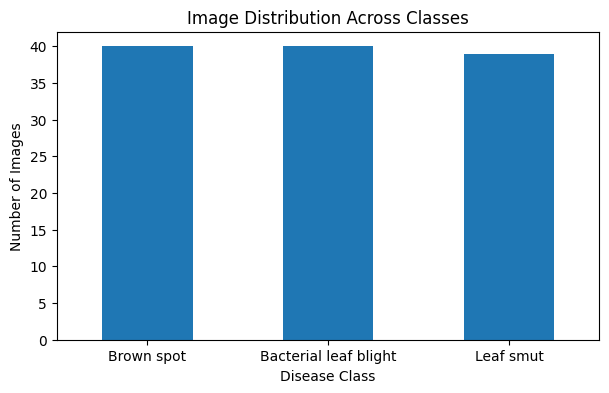

In [ ]:
# Class distribution
plt.figure(figsize=(7,4))
df['label'].value_counts().plot(kind='bar')
plt.xlabel('Disease Class')
plt.ylabel('Number of Images')
plt.title('Image Distribution Across Classes')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Check original image dimensions
image_sizes = []

for path in df['image_path']:
    with Image.open(path) as img:
        image_sizes.append(img.size)

size_df = pd.DataFrame(image_sizes, columns=['Width', 'Height'])

print("Image dimensions before resizing:")
print(size_df.describe())

Image dimensions before resizing:
             Width      Height
count   119.000000  119.000000
mean   2383.638655  707.739496
std    1123.528972  311.657582
min     250.000000   71.000000
25%    1074.000000  377.000000
50%    3081.000000  897.000000
75%    3081.000000  897.000000
max    3081.000000  900.000000


In [ ]:
# Check image color channels
sample_img = Image.open(df['image_path'].iloc[0])
print("Image mode:", sample_img.mode)
print("Number of channels:", len(sample_img.getbands()))

Image mode: RGB
Number of channels: 3


####**Display Sample Images**

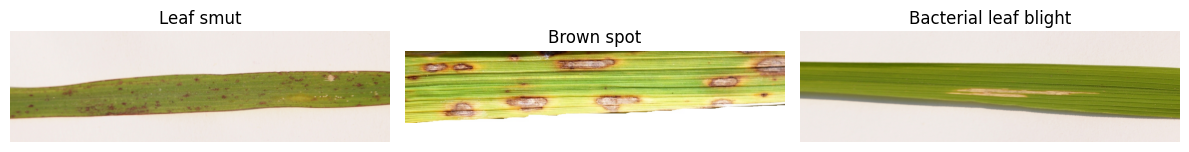

In [ ]:
# Display one sample image from each disease class

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

classes = df['label'].unique()

for i, class_name in enumerate(classes):
    image_path = df[df['label'] == class_name].iloc[0]['image_path']
    img = Image.open(image_path)

    axes[i].imshow(img)
    axes[i].set_title(class_name)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

###**Image Preprocessing & Create X, y**

In [ ]:
# Resize images and create input (X) and target (y)

IMG_SIZE = 128

X = []
y = []

class_names = ['Leaf smut', 'Brown spot', 'Bacterial leaf blight']

label_map = {
    'Leaf smut': 0,
    'Brown spot': 1,
    'Bacterial leaf blight': 2
}

for _, row in df.iterrows():
    img = Image.open(row['image_path']).convert('RGB')
    img = img.resize((IMG_SIZE, IMG_SIZE))

    X.append(np.array(img))
    y.append(label_map[row['label']])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (119, 128, 128, 3)
y shape: (119,)


In [ ]:
# One-hot encode the labels

from tensorflow.keras.utils import to_categorical

y_categorical = to_categorical(y, num_classes=3)

print("Original y shape:", y.shape)
print("One-hot encoded y shape:", y_categorical.shape)
print("First 5 encoded labels:")
print(y_categorical[:5])

Original y shape: (119,)
One-hot encoded y shape: (119, 3)
First 5 encoded labels:
[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]



###**Train-Test Split**

In [ ]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (95, 128, 128, 3)
X_test : (24, 128, 128, 3)
y_train: (95,)
y_test : (24,)


###**Normalize Image Pixel Values**

In [ ]:
# Normalize pixel values from 0-255 to 0-1

X_train = X_train / 255.0
X_test = X_test / 255.0

print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Minimum: 0.0
Maximum: 1.0


###**Display Training Images**

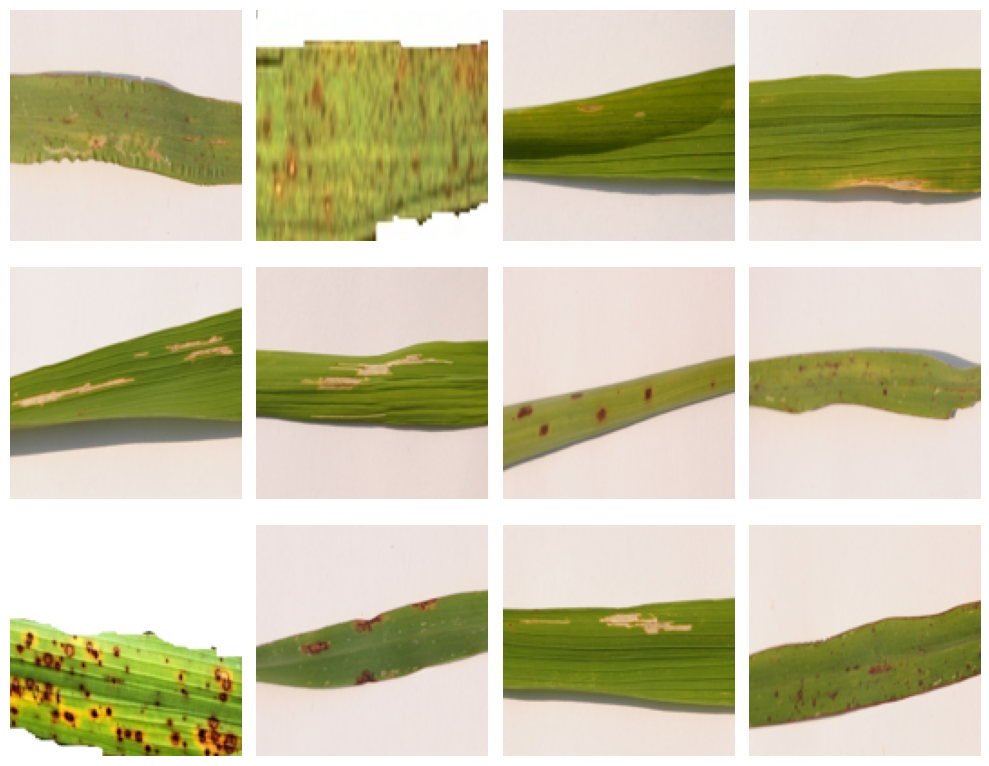

In [ ]:
# Display some training images

plt.figure(figsize=(10, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

###**CNN Model Building**


In [ ]:
# Build a CNN model for rice leaf disease classification

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(128, 128, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(3, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the CNN model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
print(model)

<Sequential name=sequential, built=True>


In [ ]:
# Train the CNN model without data augmentation

history_before = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 499ms/step - accuracy: 0.2368 - loss: 1.2846 - val_accuracy: 0.3684 - val_loss: 1.1041
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 747ms/step - accuracy: 0.3816 - loss: 1.0848 - val_accuracy: 0.3684 - val_loss: 1.0431
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 454ms/step - accuracy: 0.4737 - loss: 1.0110 - val_accuracy: 0.4737 - val_loss: 0.9857
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 447ms/step - accuracy: 0.5395 - loss: 0.9400 - val_accuracy: 0.4737 - val_loss: 0.8955
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 439ms/step - accuracy: 0.5263 - loss: 0.8490 - val_accuracy: 0.6316 - val_loss: 0.8264
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 484ms/step - accuracy: 0.6184 - loss: 0.8135 - val_accuracy: 0.6842 - val_loss: 0.8010
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 701ms/step - accuracy: 0.6316 - loss: 0.7438 - val_accuracy: 0.5789 - val_loss: 0.8127
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 466ms/step - accuracy: 0.7237 - loss: 0.6953 - val_accuracy: 0.7368 - val_loss:

In [ ]:
# Evaluate the CNN model before data augmentation

loss_before, accuracy_before = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Before Augmentation Accuracy:", accuracy_before * 100, "%")

Before Augmentation Accuracy: 62.5 %


###**Data Augmentation**

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True
)

datagen.fit(X_train)

In [ ]:
# Train the CNN model using augmented training images

history_aug = model.fit(
    datagen.flow(X_train, y_train, batch_size=16),
    epochs=30,
    validation_data=(X_test, y_test)
)

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 499ms/step - accuracy: 0.7158 - loss: 0.7217 - val_accuracy: 0.6667 - val_loss: 1.0167
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 574ms/step - accuracy: 0.8421 - loss: 0.5037 - val_accuracy: 0.7917 - val_loss: 0.5639
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 773ms/step - accuracy: 0.7368 - loss: 0.6736 - val_accuracy: 0.8333 - val_loss: 0.5410
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 482ms/step - accuracy: 0.7579 - loss: 0.5516 - val_accuracy: 0.8333 - val_loss: 0.5391
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 509ms/step - accuracy: 0.8105 - loss: 0.5246 - val_accuracy: 0.8333 - val_loss: 0.5127
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 531ms/step - accuracy: 0.8105 - loss: 0.4806 - val_accuracy: 0.8333 - val_loss: 0.4992
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 686ms/step - accuracy: 0.8211 - loss: 0.4734 - val_accuracy: 0.8333 - val_loss: 0.6082
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 500ms/step - accuracy: 0.6211 - loss: 0.7378 - val_accuracy: 0.7917 - val_loss:

In [ ]:
# Evaluate the CNN model after data augmentation

loss_after, accuracy_after_augmentation = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("After Augmentation Accuracy:", accuracy_after_augmentation * 100, "%")

After Augmentation Accuracy: 91.66666865348816 %


###**Compare Before and After Augmentation**

In [ ]:

comparison = pd.DataFrame({
    'Stage': ['Before Augmentation', 'After Augmentation'],
    'Accuracy (%)': [
        accuracy_before * 100,
        accuracy_after_augmentation * 100
    ]
})

comparison

,Stage,Accuracy (%)
0,Before Augmentation,62.500000
1,After Augmentation,91.666669


In [ ]:
# Evaluate the final CNN model

loss_final, accuracy_final = model. evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Final Test Accuracy:", accuracy_final * 100, "%")

Final Test Accuracy: 91.66666865348816 %


###**Adding Callbacks**

In [ ]:
# Add callbacks to reduce overfitting and improve training

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2
)

In [ ]:
# Train the augmented CNN model with callbacks

history_final = model.fit(
    datagen.flow(X_train, y_train, batch_size=16),
    epochs=30,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 529ms/step - accuracy: 0.9053 - loss: 0.2126 - val_accuracy: 0.8750 - val_loss: 0.4622 - learning_rate: 0.0010
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 504ms/step - accuracy: 0.9263 - loss: 0.1981 - val_accuracy: 0.8750 - val_loss: 0.4594 - learning_rate: 0.0010
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 805ms/step - accuracy: 0.9158 - loss: 0.2081 - val_accuracy: 0.9167 - val_loss: 0.4132 - learning_rate: 0.0010
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 519ms/step - accuracy: 0.9579 - loss: 0.1381 - val_accuracy: 0.8333 - val_loss: 0.6223 - learning_rate: 0.0010
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 525ms/step - accuracy: 0.8842 - loss: 0.3280 - val_accuracy: 0.8750 - val_loss: 0.4265 - learning_rate: 0.0010
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 527ms/step - accuracy: 0.8947 - loss: 0.2437 - val_accuracy: 0.9167 - val_loss: 0.4138 - learning_rate: 5.0000e-04
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 716ms/step - accuracy: 0.9053 - loss: 0.2017 - val_accura

In [ ]:
# Evaluate the final CNN model

loss_final, accuracy_final = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Final Test Accuracy:", accuracy_final * 100, "%")

Final Test Accuracy: 91.66666865348816 %


##**Task 2 – Model Building and Classification**

Data augmentation and callbacks are used to improve the model's generalization and classification performance.

###**Classification Report**

In [ ]:
# Generate predictions and display the classification report

from sklearn.metrics import classification_report

y_pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step
                       precision    recall  f1-score   support

            Leaf smut       0.80      1.00      0.89         8
           Brown spot       1.00      0.75      0.86         8
Bacterial leaf blight       1.00      1.00      1.00         8

             accuracy                           0.92        24
            macro avg       0.93      0.92      0.92        24
         weighted avg       0.93      0.92      0.92        24



In [ ]:
# Find the class with the lowest F1-score

report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    output_dict=True
)

f1_scores = {}

for class_name in class_names:
    f1_scores[class_name] = report[class_name]['f1-score']

lowest_class = min(f1_scores, key=f1_scores.get)

print("Class with the lowest F1-score:", lowest_class)
print("Lowest F1-score:", f1_scores[lowest_class])

Class with the lowest F1-score: Brown spot
Lowest F1-score: 0.8571428571428571


### Classification Report Interpretation

The classification report provides precision, recall, and F1-score for each disease class.

The class with the lowest F1-score indicates the class where the model has comparatively more difficulty in classification.

The lower performance may be related to the small dataset size and similarities between the visual features of different rice leaf diseases.

### Baseline vs Augmented Model


The CNN model was evaluated before and after applying data augmentation.

Data augmentation improved the model's performance compared with the baseline model. The final model achieved a test accuracy of 91.67%.

This indicates that data augmentation helped the model learn more robust features for rice leaf disease classification.

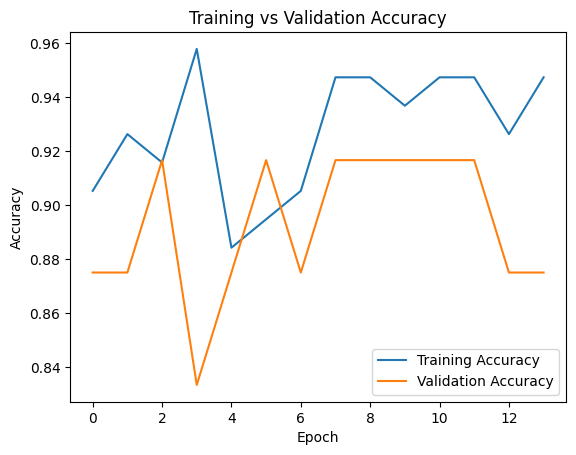

In [ ]:
# Plot training and validation accuracy

plt.plot(history_final.history['accuracy'], label='Training Accuracy')
plt.plot(history_final.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = "/content/lssss.png"

img = image.load_img(img_path, target_size=(128, 128))
img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)

predicted_class = np.argmax(prediction, axis=1)[0]

classes = [
    "Leaf smut",
    "Brown spot",
    "Bacterial leaf blight"
]

print("Predicted Disease:", classes[predicted_class])
print("Confidence:", prediction[0][predicted_class] * 100, "%")

Predicted Disease: Leaf smut
Confidence: 99.87028 %


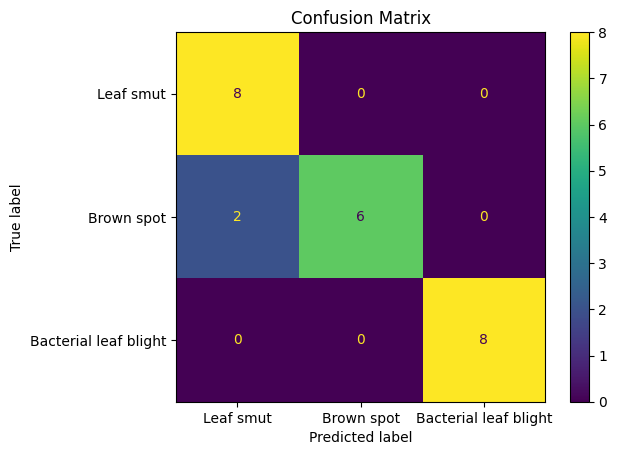

In [ ]:
# Display the confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

Number of misclassified images: 2


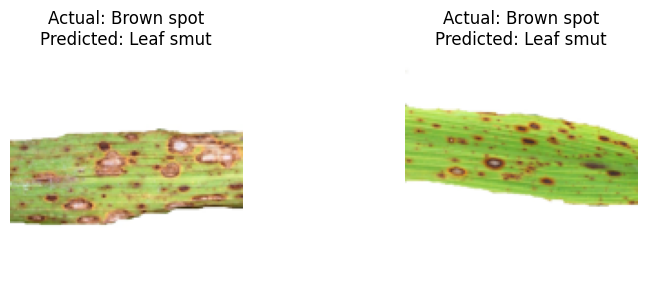

In [ ]:
# Display misclassified images

misclassified = np.where(y_test != y_pred)[0]

print("Number of misclassified images:", len(misclassified))

plt.figure(figsize=(12, 8))

for i, idx in enumerate(misclassified[:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[idx])
    plt.title(
        f"Actual: {class_names[y_test[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

### Misclassified Images Analysis

The model misclassified 2 images in the test set. Both misclassified images actually belonged to the Brown spot class but were predicted as Leaf smut.

This indicates that the model may have some difficulty distinguishing between Brown spot and Leaf smut based on their visual features. The small dataset size may also contribute to these misclassifications.

In [ ]:
# Save the trained CNN model

model.save('/content/rice_leaf_disease_cnn.h5')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Save the trained model in Keras format

model.save('/content/rice_leaf_disease_cnn.keras')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = "/content/lssss.png"

img = image.load_img(img_path, target_size=(128, 128))
img_array = image.img_to_array(img)

img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_class = np.argmax(prediction, axis=1)[0]

classes = [
    "Bacterial leaf blight",
    "Brown spot",
    "Leaf smut"
]

print("Predicted Disease:", classes[predicted_class])
print("Confidence:", prediction[0][predicted_class] * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
Predicted Disease: Bacterial leaf blight
Confidence: 99.98802 %


 building a second model

In [ ]:
# Build a second CNN model with a different architecture

model2 = Sequential([
    Input(shape=(128, 128, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(3, activation='softmax')
])

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 124, 124, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 58, 58, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 53824)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     6,889,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,955,555 (26.53 MB)

 Trainable params: 6,955,555 (26.53 MB)

 Non-trainable params: 0 (0.00 B)

training model

In [ ]:
# Compile and train the second CNN model

model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_model2 = model2.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.2632 - loss: 1.7809 - val_accuracy: 0.3684 - val_loss: 1.0790
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.2632 - loss: 1.1125 - val_accuracy: 0.3684 - val_loss: 1.0930
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.5000 - loss: 1.0427 - val_accuracy: 0.5789 - val_loss: 0.9514
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5395 - loss: 0.9284 - val_accuracy: 0.3684 - val_loss: 1.1529
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.6184 - loss: 0.8977 - val_accuracy: 0.7895 - val_loss: 0.8154
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.6184 - loss: 0.8093 - val_accuracy: 0.5263 - val_loss: 0.7763
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.6711 - loss: 0.6699 - val_accuracy: 0.7895 - val_loss: 0.7154
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.7895 - loss: 0.5563 - val_accuracy: 0.6842 - val_loss: 0.6924
Epoch 9/20
5

In [ ]:
# Evaluate the second CNN model

loss_model2, accuracy_model2 = model2.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Model 2 Test Accuracy:", accuracy_model2 * 100, "%")


Model 2 Test Accuracy: 58.33333134651184 %


In [ ]:
# Compare the test accuracy of both CNN models

model_comparison = pd.DataFrame({
    'Model': ['CNN Model 1', 'CNN Model 2'],
    'Test Accuracy (%)': [
        accuracy_final * 100,
        accuracy_model2 * 100
    ]
})

model_comparison

,Model,Test Accuracy (%)
0,CNN Model 1,87.500000
1,CNN Model 2,58.333331


## Model Comparison and Final Model Selection

Two different CNN architectures were trained and evaluated.

- CNN Model 1 achieved **87.50%** test accuracy.
- CNN Model 2 achieved **58.33%** test accuracy.

Based on the test accuracy, **CNN Model 1** was selected as the final model because it performed better than CNN Model 2 on the test dataset.

## Challenges

The main challenges faced during this project were:

- The dataset contains a limited number of images.
- The images have different sizes and required resizing.
- The model showed signs of overfitting during training.
- Model performance varied between different CNN architectures.
- Some rice leaf diseases have similar visual symptoms, making classification more difficult.

## Conclusion

The Rice Leaf Disease Prediction project developed a CNN-based image classification model to classify rice leaves into three disease classes: Leaf smut, Brown spot, and Bacterial leaf blight.

The project included data exploration, image resizing, normalization, label encoding, data augmentation, CNN model training, and evaluation using accuracy, precision, recall, F1-score, and confusion matrix.

The final model achieved a test accuracy of 87.50%. The classification report showed that Brown spot had the lowest F1-score of 85.71% among the three classes.

The model misclassified 2 test images. Both belonged to the Brown spot class but were predicted as Leaf smut. This shows that distinguishing these two disease classes can be challenging based on their visual features.

One of the main limitations of this project is the small dataset size. As a future improvement, Transfer Learning models such as MobileNet can be explored to improve the model's performance and generalization.